# Lab 5: Hierarchical and DBSCAN Clustering on the Wine Dataset

Name: Sandip Sitaula
Course: MSCS 634 - Advanced Big Data and Data Mining
Lab: Lab 5 - Hierarchical and DBSCAN Clustering

## Step 1: Data preparation and exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
wine = load_wine(as_frame=True)
df = wine.data
y = wine.target          # true wine classes, used only to evaluate (never to cluster)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


In [4]:
print("Missing values:", int(df.isna().sum().sum()))
print("Real class sizes:", y.value_counts().sort_index().to_dict())

Missing values: 0
Real class sizes: {0: 59, 1: 71, 2: 48}


Mean after scaling: -0.0 | Std after scaling: 1.0 - 1.0
Variance kept by the 2 PCA axes: 0.554


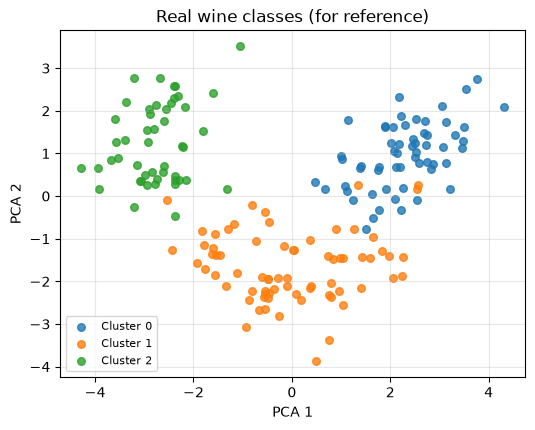

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(df)
print("Mean after scaling:", X.mean(axis=0).round(2).max(), "| Std after scaling:", X.std(axis=0).round(2).min(), "-", X.std(axis=0).round(2).max())

# PCA is only used to draw the 13-D data in 2-D. Clusters are made with all 13 features.
pca = PCA(n_components=2, random_state=42)
X2 = pca.fit_transform(X)
print("Variance kept by the 2 PCA axes:", pca.explained_variance_ratio_.sum().round(3))

def scatter(ax, labels, title):
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(X2[m, 0], X2[m, 1], c="black", marker="x", s=35, label="Noise")
        else:
            ax.scatter(X2[m, 0], X2[m, 1], s=30, alpha=0.8, label=f"Cluster {lab}")
    ax.set(title=title, xlabel="PCA 1", ylabel="PCA 2"); ax.legend(fontsize=8)

def scores(labels):
    # Silhouette needs at least 2 clusters; noise points (-1) are left out of the silhouette only
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    sil = silhouette_score(X[mask], labels[mask]) if n_cl >= 2 and mask.sum() > n_cl else np.nan
    return {"clusters": n_cl, "noise": int((~mask).sum()), "silhouette": sil,
            "homogeneity": homogeneity_score(y, labels), "completeness": completeness_score(y, labels),
            "ARI": adjusted_rand_score(y, labels)}

fig, ax = plt.subplots(figsize=(6, 4.5)); scatter(ax, y.values, "Real wine classes (for reference)"); plt.show()

**Observations.** The Wine data has 178 wines and 13 chemical measurements. There are no missing values. The real wines belong to 3 classes (59, 71 and 48 wines). I do not use these classes to make the clusters. I only use them at the end to check how good the clusters are. The features have very different sizes (for example, `proline` goes up to 1680 but `hue` is below 2). Without scaling, `proline` would control the distances. So I standardized all features (mean 0, standard deviation 1). The data has 13 features, so for the plots I use PCA to draw it in 2D. The two PCA axes keep only 55% of the information, so the plots are a rough picture. The clusters themselves use all 13 features.

## Step 2: Hierarchical clustering

In [6]:
rows, fits = [], {}
for k in [2, 3, 4, 5]:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    fits[k] = lab
    rows.append({"n_clusters": k, **scores(lab)})
hier_df = pd.DataFrame(rows).set_index("n_clusters").round(3)
hier_df

,clusters,noise,silhouette,homogeneity,completeness,ARI
n_clusters,,,,,,
2,2,0,0.267,0.444,0.774,0.439
3,3,0,0.277,0.790,0.783,0.790
4,4,0,0.226,0.790,0.649,0.657
5,5,0,0.187,0.811,0.576,0.583


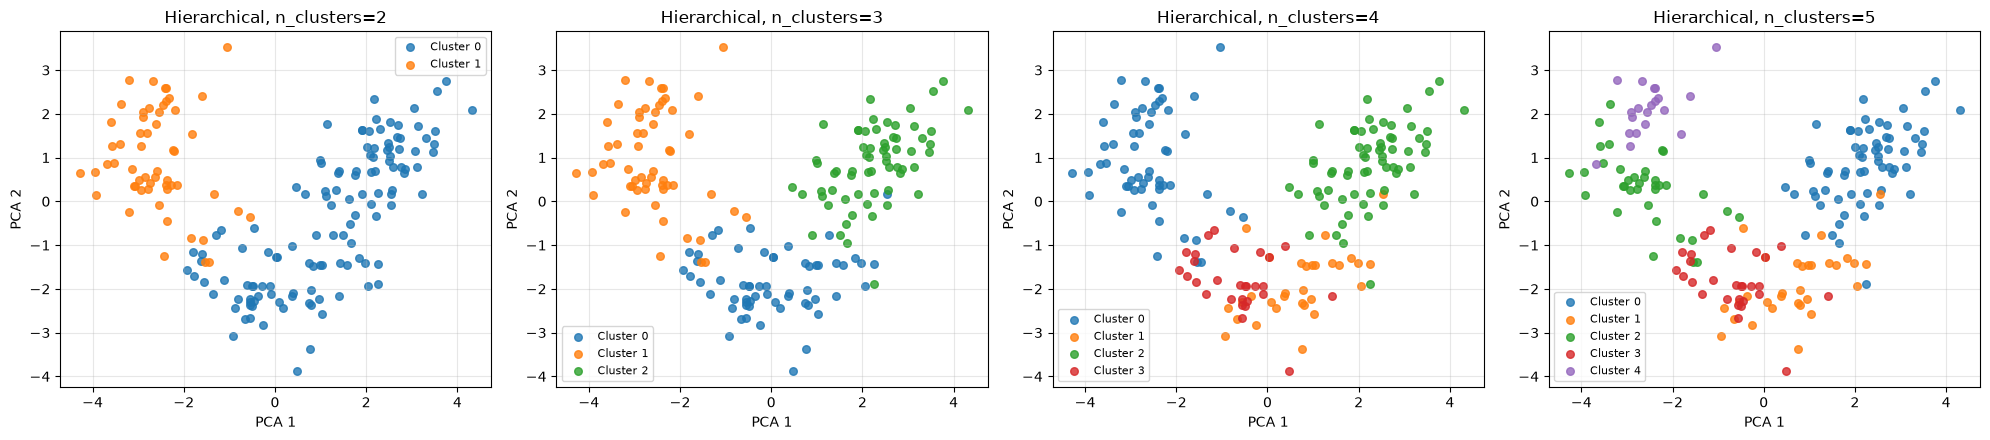

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, k in zip(axes, [2, 3, 4, 5]):
    scatter(ax, fits[k], f"Hierarchical, n_clusters={k}")
plt.tight_layout(); plt.show()

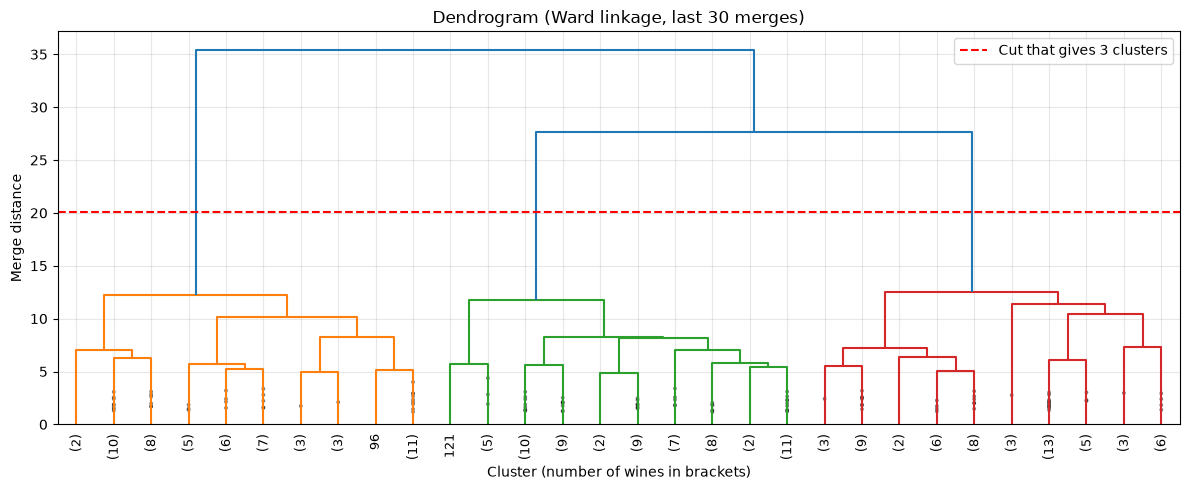

Last merge distances (from the top): [35.4 27.7 12.6 12.2 11.7]


In [8]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True, ax=ax)
cut = (Z[-2, 2] + Z[-3, 2]) / 2    # a height between the last 2 big merges, which leaves 3 clusters
ax.axhline(cut, color="red", ls="--", label="Cut that gives 3 clusters")
ax.set(title="Dendrogram (Ward linkage, last 30 merges)", xlabel="Cluster (number of wines in brackets)", ylabel="Merge distance"); ax.legend()
plt.tight_layout(); plt.show()
print("Last merge distances (from the top):", Z[-5:, 2].round(1)[::-1])

**Result.** I tried 2, 3, 4 and 5 clusters with Ward linkage. Three clusters gave the best result: silhouette 0.277, homogeneity 0.790, completeness 0.783 and ARI 0.790. With 2 clusters, two real classes are forced together, so homogeneity is low (0.444). With 4 and 5 clusters, real classes are cut into pieces, so completeness drops (0.649 and 0.576) and the silhouette gets worse (0.226 and 0.187). The silhouette scores are all low, which means the clusters touch each other a little. The scatter plots show the same thing: the groups are clear but their borders overlap.

**Dendrogram.** The dendrogram is the tree of merges. The height of a line is the distance at which two clusters are joined. The last merges have heights 35.4, 27.7, then 12.6, 12.2 and 11.7. There is a big drop from 27.7 to 12.6. This means the tree has 3 big groups that are far from each other, and below that, the groups are joined at similar distances. The red line cuts the tree in that gap and gives 3 clusters, which agrees with the best result in the table. Compared with the real classes, the 3 clusters are good: all 59 wines of class 0 and all 48 wines of class 2 are each in their own cluster, and only 13 of the 71 wines of class 1 are in the wrong cluster.

## Step 3: DBSCAN clustering

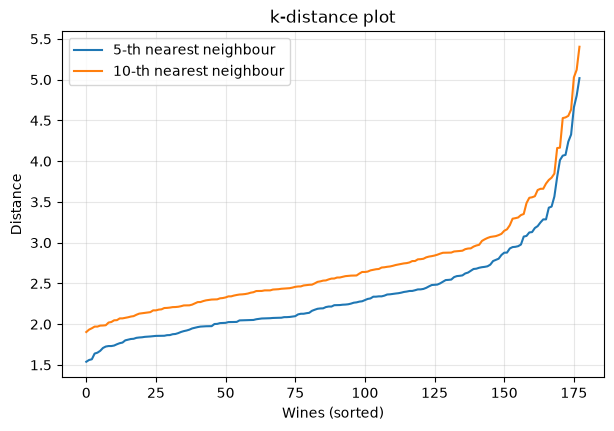

In [9]:
# k-distance plot: helps to choose eps (look for the 'elbow')
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in (5, 10):
    d, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
    ax.plot(np.sort(d[:, -1]), label=f"{k}-th nearest neighbour")
ax.set(title="k-distance plot", xlabel="Wines (sorted)", ylabel="Distance"); ax.legend(); plt.show()

In [10]:
rows = []
for ms in [3, 5, 10]:
    for eps in [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        rows.append({"eps": eps, "min_samples": ms, **scores(lab)})
db_df = pd.DataFrame(rows).round(3)
db_df

,eps,min_samples,clusters,noise,silhouette,homogeneity,completeness,ARI
0,1.5,3,8,147,0.331,0.189,0.251,0.040
1,2.0,3,5,64,0.211,0.442,0.372,0.287
2,2.5,3,1,23,NaN,0.067,0.189,0.008
3,3.0,3,2,7,0.239,0.031,0.135,-0.007
4,3.5,3,2,3,0.231,0.029,0.187,-0.009
5,4.0,3,2,0,0.222,0.014,0.184,-0.005
6,1.5,5,0,178,NaN,0.000,1.000,0.000
7,2.0,5,5,85,0.240,0.362,0.325,0.220
8,2.5,5,1,24,NaN,0.058,0.158,0.005
9,3.0,5,1,11,NaN,0.031,0.145,-0.006


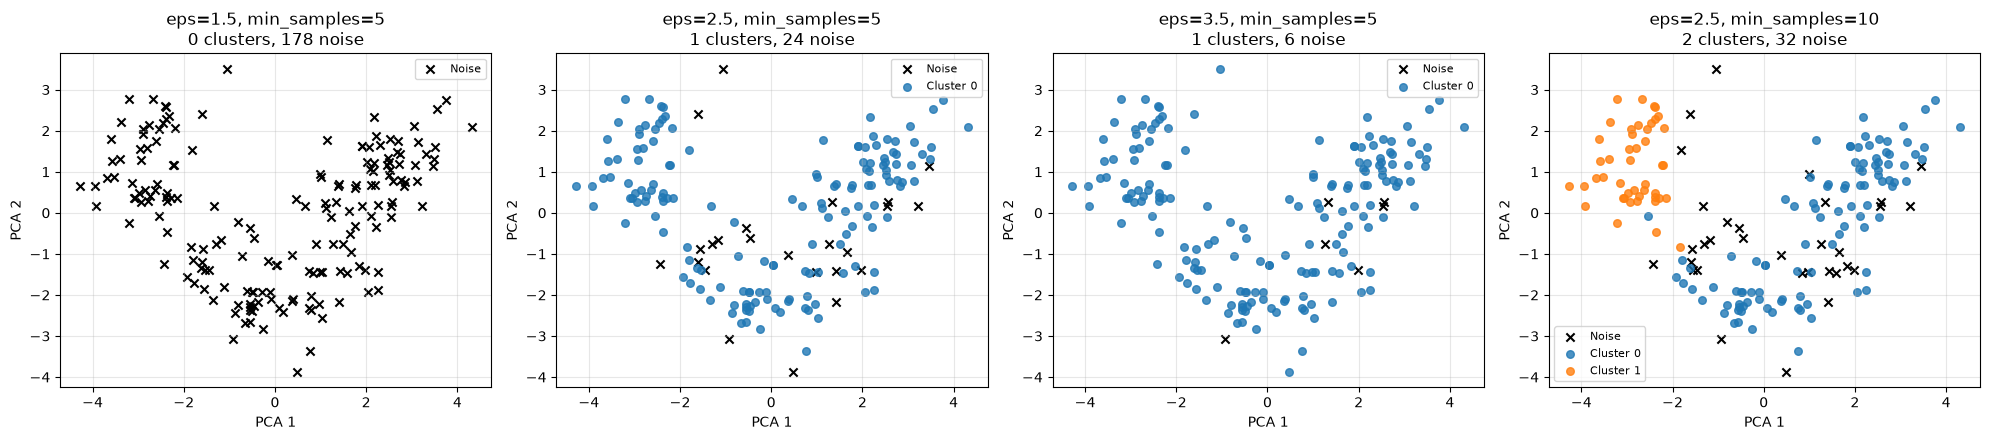

In [11]:
# Four settings that show how the parameters change the result
picks = [(1.5, 5), (2.5, 5), (3.5, 5), (2.5, 10)]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
db_fits = {}
for ax, (eps, ms) in zip(axes, picks):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X); db_fits[(eps, ms)] = lab
    s = scores(lab)
    scatter(ax, lab, f"eps={eps}, min_samples={ms}\n{s['clusters']} clusters, {s['noise']} noise")
plt.tight_layout(); plt.show()

In [12]:
# Pick the best setting: the one with the highest ARI, as long as it has at least 2 clusters
cand = db_df[db_df["clusters"] >= 2].sort_values("ARI", ascending=False)
best = cand.iloc[0]
print("Best DBSCAN setting:", dict(best[["eps", "min_samples"]]))
db_best = DBSCAN(eps=best["eps"], min_samples=int(best["min_samples"])).fit_predict(X)
final = pd.DataFrame({"Hierarchical (k=3)": scores(fits[3]), "DBSCAN (best)": scores(db_best)}).T.round(3)
final

Best DBSCAN setting: {'eps': np.float64(2.5), 'min_samples': np.float64(10.0)}


,clusters,noise,silhouette,homogeneity,completeness,ARI
Hierarchical (k=3),3.0,0.0,0.277,0.790,0.783,0.790
DBSCAN (best),2.0,32.0,0.323,0.504,0.560,0.424


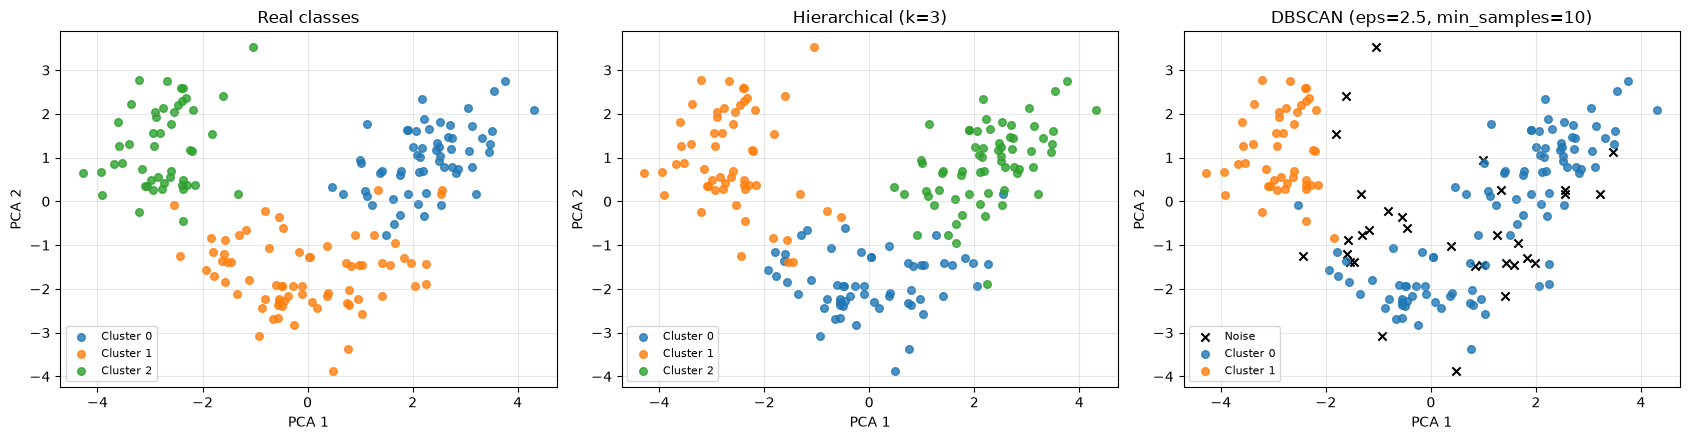

DBSCAN label (-1 = noise)  -1   0   1
true class                           
0                           3  56   0
1                          25  45   1
2                           4   0  44
Hierarchical label   0   1   2
true class                    
0                    0   0  59
1                   58   8   5
2                    0  48   0


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
scatter(axes[0], y.values, "Real classes")
scatter(axes[1], fits[3], "Hierarchical (k=3)")
scatter(axes[2], db_best, f"DBSCAN (eps={best['eps']}, min_samples={int(best['min_samples'])})")
plt.tight_layout(); plt.show()
print(pd.crosstab(y, db_best, rownames=["true class"], colnames=["DBSCAN label (-1 = noise)"]))
print(pd.crosstab(y, fits[3], rownames=["true class"], colnames=["Hierarchical label"]))

**How the parameters work.** `eps` is the radius around a wine. `min_samples` is how many wines must be inside that radius for the area to count as dense. Wines in no dense area are called noise (black x). DBSCAN chooses the number of clusters by itself.

**Result.** The parameters changed the result a lot:
- **eps too small** (1.5 with min_samples 5 or 10): every wine is noise (178 of 178), so there are no clusters. With min_samples 3, there are 8 tiny clusters and 147 noise points.
- **eps too big** (3.0 and above): the dense areas join together and everything becomes 1 big cluster (or 2 with a few points). The ARI is about 0, which is no better than random.
- **A narrow middle range** (eps 2.0 to 2.5) gives something useful. The best setting I found was eps = 2.5 with min_samples = 10. It gives 2 clusters and 32 noise wines, with silhouette 0.323, homogeneity 0.504, completeness 0.560 and ARI 0.424.

**Be careful with the metrics.** The silhouette is calculated without the noise points, so it can look good even when many wines are thrown away. For example, eps 1.5 with min_samples 3 has silhouette 0.331 (the highest in the table) but 147 of the 178 wines are noise. Also, when every wine is noise, completeness shows 1.0, because noise counts as one big group. That number means nothing. So I judged DBSCAN by ARI and by how many wines are noise, not by the silhouette alone.

**What the best DBSCAN did.** The cluster table shows that DBSCAN found class 0 (56 of 59 wines) and class 2 (44 of 48 wines) well. But it could not find class 1 as its own group: 45 of those wines went into the class 0 cluster and 25 became noise. Class 1 and class 0 are close to each other and have a similar density, so DBSCAN sees them as one dense area.

## Step 4: Analysis and insights

In [14]:
final

,clusters,noise,silhouette,homogeneity,completeness,ARI
Hierarchical (k=3),3.0,0.0,0.277,0.790,0.783,0.790
DBSCAN (best),2.0,32.0,0.323,0.504,0.560,0.424


**Comparison.** Hierarchical clustering with 3 clusters was clearly better on this data. Its ARI is 0.790 against 0.424 for DBSCAN. Its homogeneity (0.790 vs 0.504) and completeness (0.783 vs 0.560) are also higher. It puts every wine in a cluster. DBSCAN has a higher silhouette (0.323 vs 0.277), but this is not fair to compare, because DBSCAN leaves out its 32 noise wines (18% of the data), and it merged two real classes. The silhouette only measures how tight and separate the clusters are. It does not say if they match the real groups.

**How the parameters changed the results.** For Hierarchical clustering, the only choice is the number of clusters, and the dendrogram and the scores both pointed to 3, so it was easy to tune. For DBSCAN, two parameters were very sensitive. A small change of eps (from 2.5 to 3.0 or from 2.0 to 1.5) moved the result from a useful clustering to all noise or one big cluster. This is probably hard to tune because the data has 13 dimensions and, after scaling, the distances between wines are large and similar, so there is no big gap in density.

**Strengths and weaknesses.**
- **Hierarchical (Ward):** Good here because the wine classes are round and about the same size. The dendrogram helps to pick the number of clusters. The weakness is that you must choose the number of clusters, and it cannot mark outliers, so every wine is forced into a cluster. It also gets slow on very large data.
- **DBSCAN:** Good at finding odd-shaped clusters and at marking outliers as noise, and you do not need to give the number of clusters. The weakness is that it uses one density for the whole data, so it fails when groups touch each other (like class 0 and class 1) or have different densities. It is also very sensitive to eps and min_samples, and it works worse in high dimensions.

**Conclusion.** For the Wine dataset, which has 3 compact groups that slightly overlap, Hierarchical clustering is the better choice. DBSCAN would be a better choice for data with strange shapes or many outliers.